## Problem statement:
 How can we segment our customers so we can better target marketing campaigns and improve retention ?

 How can we segment our customers to better target marketing campaigns and improve retention ?


In [1]:
# -*- coding: utf-8 -*-

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

kpmg = pd.read_csv('/kaggle/input/kpmg-customer-demography-cleaned-dataset/KPMG_Customer_Demography.csv')
kpmg.head()

,customer_id,First_Name,Last_Name,gender,DOB,AGE,past_3_years_bike_related_purchases,job_industry_category,wealth_segment,deceased_indicator,tenure,Owns_Car,Address,Postcode,State,Country,property_valuation
0,1,Laraine,Medendorp,Female,10/12/1953,69,93,Health,Mass Customer,N,11,Yes,060 Morning Avenue,2016,New South Wales,Australia,10
1,2,Eli,Bockman,Male,12/16/1980,42,81,Financial Services,Mass Customer,N,16,Yes,6 Meadow Vale Court,2153,New South Wales,Australia,10
2,4,Talbot,NaN,Male,10/3/1961,61,33,IT,Mass Customer,N,7,No,0 Holy Cross Court,4211,Queensland,Australia,9
3,5,Sheila-kathryn,Calton,Female,5/13/1977,45,56,NaN,Affluent Customer,N,8,Yes,17979 Del Mar Point,2448,New South Wales,Australia,4
4,6,Curr,Duckhouse,Male,9/16/1966,56,35,Retail,High Net Worth,N,13,Yes,9 Oakridge Court,3216,Victoria,Australia,9


In [2]:
kpmg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3908 entries, 0 to 3907
Data columns (total 17 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   customer_id                          3908 non-null   int64 
 1   First_Name                           3908 non-null   object
 2   Last_Name                            3787 non-null   object
 3   gender                               3908 non-null   object
 4   DOB                                  3908 non-null   object
 5   AGE                                  3908 non-null   int64 
 6   past_3_years_bike_related_purchases  3908 non-null   int64 
 7   job_industry_category                3253 non-null   object
 8   wealth_segment                       3908 non-null   object
 9   deceased_indicator                   3908 non-null   object
 10  tenure                               3908 non-null   int64 
 11  Owns_Car                             3908 n

### What is the age distribution of customers ?


<Axes: xlabel='AGE'>

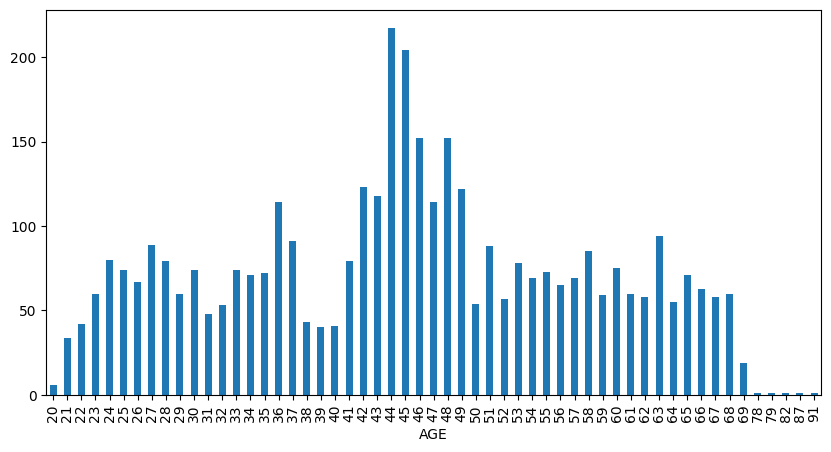

In [3]:

# group the data by age and find the frequency of each age
kpmg_age = kpmg.groupby('AGE').size()
kpmg_age.plot(kind='bar', figsize=(10,5))

# we can see that ages are normaly distributed (I GUESS) or skewed th the left

<Axes: >

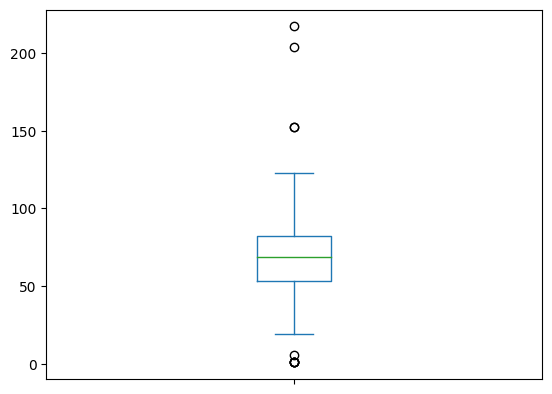

In [4]:
kpmg_age.plot(kind="box")

### Which State are most customers from ?

<Axes: xlabel='State'>

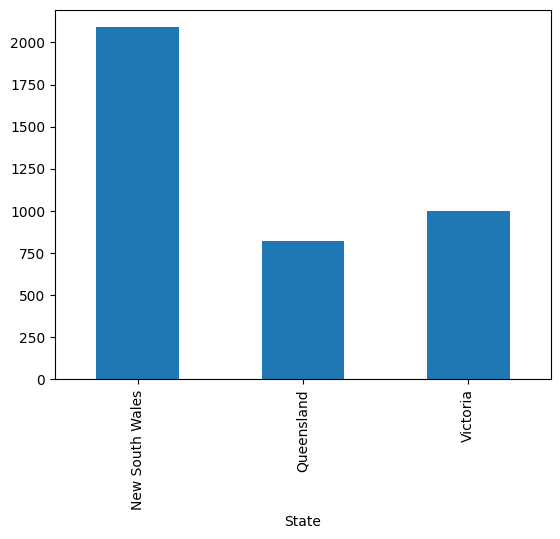

In [5]:
kpmg_state = kpmg.groupby('State').size()
kpmg_state.plot(kind='bar')

### Which wealth bracket do most of our clients fall into?

In [6]:
kpmg_welth = kpmg.groupby('wealth_segment').size()
kpmg_welth

wealth_segment
Affluent Customer     962
High Net Worth        995
Mass Customer        1951
dtype: int64

In [7]:
# cut the age column into ranges
bins = [20, 35, 50, 65, 80, 95]  
labels = ['20-35', '36-50', '51-65', '67-80', '81-95']

#create a new column
kpmg['Age_group'] = pd.cut(kpmg['AGE'], bins=bins, labels=labels)
#kpmg.head()

### What kind of age + wealth combinations buy the most bikes?


In [8]:
# group by wealth status & age group , with showing the bike purchase column mean
kpmg_wealth_age = kpmg.groupby(['wealth_segment', 'Age_group'])['past_3_years_bike_related_purchases'].mean() # this wil calculate the avg of purchase on bike in each age group in each wealth segment
kpmg_wealth_age

/tmp/ipykernel_13/2346405239.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  kpmg_wealth_age = kpmg.groupby(['wealth_segment', 'Age_group'])['past_3_years_bike_related_purchases'].mean() # this wil calculate the avg of purchase on bike in each age group in each wealth segment
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((ab

wealth_segment     Age_group
Affluent Customer  20-35        52.194215
                   36-50        49.790754
                   51-65        45.311538
                   67-80        44.911111
                   81-95        67.000000
High Net Worth     20-35        44.776000
                   36-50        49.080569
                   51-65        46.859259
                   67-80        51.269231
                   81-95              NaN
Mass Customer      20-35        51.249485
                   36-50        49.897714
                   51-65        48.773764
                   67-80        47.676190
                   81-95        74.500000
Name: past_3_years_bike_related_purchases, dtype: float64

## Customer segmentation

In [9]:
def segment_customer(row):
    if row['Age_group'] == '20-35' and row['wealth_segment'] == 'Mass Customer':
        return 'Young Mass Shopper'   # Buiseness decision: Sales to keep them our customers
    elif row['Age_group'] == '20-35' and row['wealth_segment']=='Affluent Customer' and row['past_3_years_bike_related_purchases']>=52:
        return 'Young / Bike Enthusiast / Premium Customer'   #Buiseness Decision: Introduce our newest high-performance bike — loved by young pros and city riders!
    elif row['Age_group'] == '36-50' or row['Age_group'] == '51-65' and row['wealth_segment'] == 'High Net Worth' and row['past_3_years_bike_related_purchases']>=49:
        return 'Middle-aged bike enthusiast premium customers ' #Buiseness decision: suggest luxury products
    else:
        return 'General Customer'

kpmg['Segment'] = kpmg.apply(segment_customer, axis=1)
kpmg.head()

,customer_id,First_Name,Last_Name,gender,DOB,AGE,past_3_years_bike_related_purchases,job_industry_category,wealth_segment,deceased_indicator,tenure,Owns_Car,Address,Postcode,State,Country,property_valuation,Age_group,Segment
0,1,Laraine,Medendorp,Female,10/12/1953,69,93,Health,Mass Customer,N,11,Yes,060 Morning Avenue,2016,New South Wales,Australia,10,67-80,General Customer
1,2,Eli,Bockman,Male,12/16/1980,42,81,Financial Services,Mass Customer,N,16,Yes,6 Meadow Vale Court,2153,New South Wales,Australia,10,36-50,Middle-aged bike enthusiast premium customers
2,4,Talbot,NaN,Male,10/3/1961,61,33,IT,Mass Customer,N,7,No,0 Holy Cross Court,4211,Queensland,Australia,9,51-65,General Customer
3,5,Sheila-kathryn,Calton,Female,5/13/1977,45,56,NaN,Affluent Customer,N,8,Yes,17979 Del Mar Point,2448,New South Wales,Australia,4,36-50,Middle-aged bike enthusiast premium customers
4,6,Curr,Duckhouse,Male,9/16/1966,56,35,Retail,High Net Worth,N,13,Yes,9 Oakridge Court,3216,Victoria,Australia,9,51-65,General Customer
